In [1]:
import numpy as np
import fastplotlib as fpl
import tifffile

from scipy.sparse.linalg import svds

WGPU: enumerate_adapters() is deprecated, use enumerate_adapters_sync() instead.
Unable to find extension: VK_EXT_swapchain_colorspace
WGPU: request_adapter() is deprecated, use request_adapter_sync() instead.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅ (default),AMD RADV POLARIS10 (ACO),DiscreteGPU,Vulkan,Mesa 20.3.5 (ACO)
❗ limited,"llvmpipe (LLVM 11.0.1, 256 bits)",CPU,Vulkan,Mesa 20.3.5 (LLVM 11.0.1)
✅,NVIDIA GeForce RTX 3080,DiscreteGPU,Vulkan,530.30.02
❌,"Radeon RX 570 Series (POLARIS10, DRM 3.40.0, 5.10.0-21-amd64, LLVM 11.0.1)",Unknown,OpenGL,4.6 (Core Profile) Mesa 20.3.5


To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


In [2]:
from matplotlib import pyplot as plt

In [3]:
%matplotlib inline

In [36]:
import numba

@numba.guvectorize([(numba.float32[:], numba.float32[:])], "(n)->(n)")
def rolling_percentile(trace: np.ndarray, out: np.ndarray):
    for i in range(0, trace.size - 1):
        out[i] = np.percentile(trace[i:i + 30], 5)


@numba.njit(parallel=True)
def rolling_percentile_movie(m, output):
    t, row, col = m.shape
    for i in numba.prange(row):
        for j in range(col):
            rolling_percentile(m[:, i, j], output[:, i, j])

In [39]:
sub = np.zeros(movie.shape, dtype=np.float32)
rolling_percentile_movie(movie.astype(np.float32), sub)

In [ ]:
ti

In [ ]:
del movie

In [42]:
tifffile.imwrite("./dendrites_rect_filtered.tif", sub)

In [6]:
sub = tifffile.imread("./dendrites_rect_filtered.tif")

In [3]:
from sklearn.metrics import pairwise_distances
from tqdm import tqdm

RFBOutputContext()

JupyterWgpuCanvas()
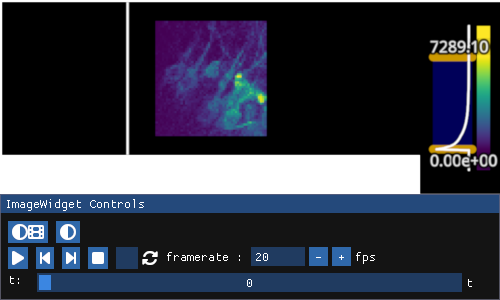

In [7]:
iw_sub = fpl.ImageWidget(sub, cmap="viridis")
iw_sub.show()

In [67]:
period_1 = (4255, 4420)
period_2 = (9250, 9800)
period_3 = (14150, 14490)

RFBOutputContext()

JupyterWgpuCanvas()
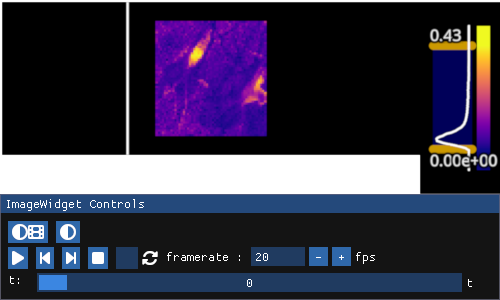

In [9]:
labels = np.load("./dendrites_15_spatial.npy").swapaxes(0, 1).T
fpl.ImageWidget(labels).show()

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/tools/_histogram_lut.py:217: RuntimeWarning: Converting input from bool to <class 'numpy.uint8'> for compatibility.
  hist, edges = np.histogram(data_ss, bins=self._nbins)


JupyterWgpuCanvas()
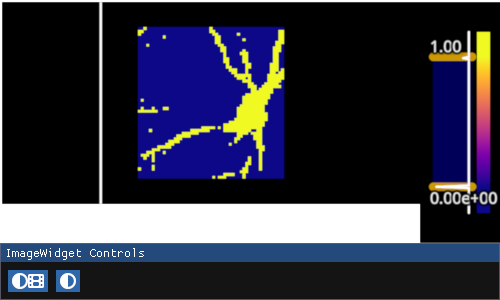

In [10]:
A = labels[10]
A[A < 0.08] = 0
A = A.astype(bool)

fpl.ImageWidget(A).show()

In [46]:
A_ixs = np.where(A)
A_shape = A.shape

In [47]:
def recover(pixels: np.ndarray, shape: tuple[int, int], indices: np.ndarray) -> np.ndarray:
    r = np.zeros(shape)
    r[indices] = pixels
    return r

In [68]:
Ya = sub[slice(*period_2), *A_ixs].T

In [69]:
Ya.shape

(437, 550)

In [70]:
from ipywidgets import IntSlider, VBox, HBox

In [71]:
iw_rec = fpl.ImageWidget(recover(Ya[:, 0], A.shape, A_ixs), cmap="viridis", figure_kwargs={"size": (520, 600)})
iw_rec.show()

fig_heatmap = fpl.Figure(size=(600, 600))
fig_heatmap[0, 0].add_image(Ya, cmap="viridis")

ts = IntSlider(min=0, max=Ya.shape[1] - 1, value=0)

def update_time(change):
    ix = change["new"]
    iw_rec.set_data(recover(Ya[:, ix], A.shape, A_ixs))

ts.observe(update_time, "value")

HBox([VBox([iw_rec.show(), ts]), fig_heatmap.show()])

RFBOutputContext()

RFBOutputContext()

In [53]:
Ya.nbytes / 1024 / 1024

0.5834579467773438

In [78]:
from tqdm import tqdm
from scipy.linalg import hankel

In [85]:
w2 = 100 * 2
w = int(w2 / 2)
t = 200

Ys = list()
Ps = list()
Fs = list()

n_pixels = Ya.shape[0]

for i in tqdm(range(n_pixels)):
    y = hankel(Ya[i, t: t + w2], Ya[i, t:t + w2])
    p = np.flipud(y[:w])
    f = y[w:]

    Ps.append(p)
    Fs.append(f)

P_F_shape = (w * n_pixels, w2)

100%|████████████████████████████████████████████████████████████████████| 437/437 [00:00<00:00, 35974.70it/s]


In [86]:
y.shape, p.shape, f.shape

((200, 200), (100, 200), (100, 200))

In [87]:
P_F_shape

(43700, 200)

In [88]:
P = np.zeros(P_F_shape)
F = np.zeros(P_F_shape)

In [89]:
for i in tqdm(range(n_pixels)):
    P[i::n_pixels] = Ps[i]
    F[i::n_pixels] = Fs[i]

100%|████████████████████████████████████████████████████████████████████| 437/437 [00:00<00:00, 15682.53it/s]


In [ ]:
iw_embedding = fpl.ImageWidget(F, cmap="viridis")
iw_embedding.show()

In [97]:
iw_embedding.close()

In [98]:
H = (F @ P.T) / P.shape[1]

In [100]:
from itertools import product

In [101]:
print("Computing Hp")
Hp = np.zeros((w ** 2, n_pixels ** 2))

for row_ix, (block_i, block_j) in enumerate(product(*[range(0, w * n_pixels, n_pixels)] * 2)):
    Hp[row_ix] = H.T[block_i:block_i + n_pixels, block_j:block_j + n_pixels].ravel()

del H

Computing Hp


In [23]:
Hp.shape

(6400, 116964)

In [102]:
u, s, v = svds(Hp, k=6)

In [109]:
u = u[:, ::-1]
s = s[::-1]
v = v[::-1]

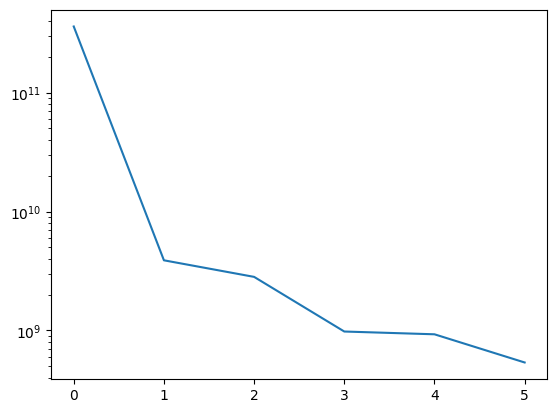

In [283]:
plt.plot(s)
plt.semilogy()
plt.show()

In [ ]:
np.linalg.matrix_rank(Hp)

In [113]:
Y.shape

(270, 437)

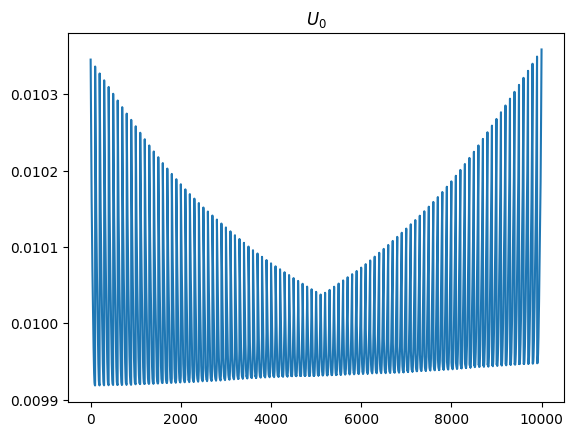

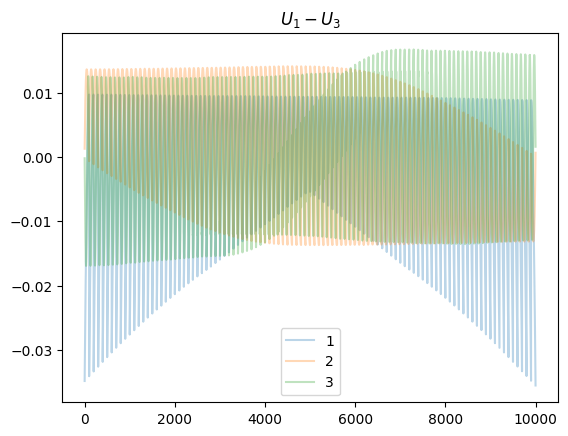

In [301]:
plt.plot(u[:, 0])
plt.title("$U_0$")
plt.show()

for i in range(1, 4):
    plt.plot(u[:, i], label=i, alpha=0.3)

plt.legend()
plt.title("$U_1 - U_3$")
plt.show()

In [314]:
# time x time
B = v[3].reshape(Y.shape[1], Y.shape[1])

In [315]:
B.shape

(437, 437)

In [316]:
img0 = recover(B[3], A.shape, A_ixs)

### Do eigendecomp of each V_i, and then kronekar with U ??

### I think that each B_i cov matrix here represents: For this given temporal mode how do the pixels co-vary

# USE CURSOR TOOL WITH STICK ON COV MATRIX, DISPLAY ROW AND COLUMN IMAGES

# Here it makes sense for V to be negative, reflect the differences between the cell body and dendrites

RFBOutputContext()

JupyterWgpuCanvas(css_height='400px', css_width='700px')
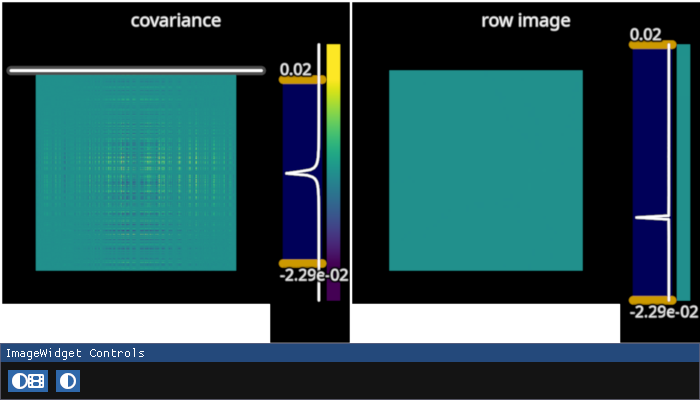

In [317]:
figure_kwargs = {"size": (700, 400), "controller_ids": [[0, 1]]}

iw = fpl.ImageWidget(
    data=[B, img0],
    cmap="viridis",  # diverging colormap
    names=["covariance", "row image"],
    figure_kwargs=figure_kwargs,
)

g = iw.managed_graphics[1]
g.vmin, g.vmax = B.min(), B.max()

selector_cov = iw.managed_graphics[0].add_linear_selector(axis="y")

@selector_cov.add_event_handler("selection")
def update_img(ev):
    ix = ev.get_selected_index()

    img = recover(B[ix], A.shape, A_ixs)

    iw.managed_graphics[1].data = img

iw.show()

In [318]:
iw.cmap = "bwr"

In [307]:
u_s, s_s, v_s = np.linalg.svd(B)

[]

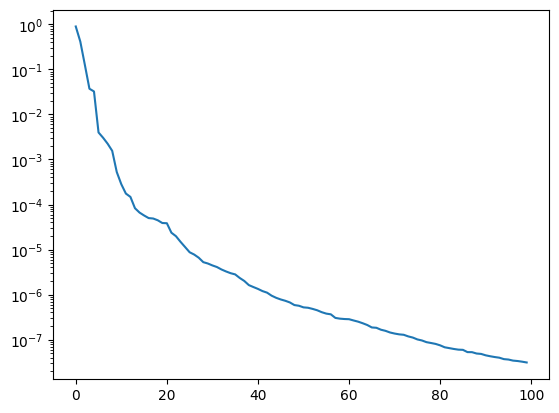

In [308]:
plt.plot(s_s[:100])
plt.semilogy()

In [309]:
u_s_images = np.dstack([recover(u_s[i], A.shape, A_ixs).T for i in range(u_s.shape[1])]).T
v_s_images = np.dstack([recover(v_s[i], A.shape, A_ixs).T for i in range(v_s.shape[1])]).T

RFBOutputContext()

JupyterWgpuCanvas()
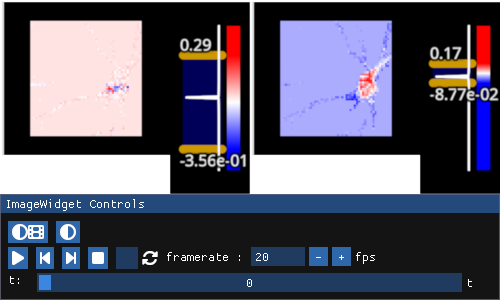

In [310]:
iw_s = fpl.ImageWidget([u_s_images, v_s_images], cmap="bwr")
iw_s.show()

In [197]:
np.linalg.norm((B - B.T) / np.linalg.norm(B, ord="fro"), ord="fro")

np.float64(0.0014938467234763067)

In [198]:
from scipy.sparse.linalg import eigsh

In [199]:
evals, evecs = eigsh(B, k=10)

In [200]:
evals = evals[::-1]
evecs = evecs[::-1]

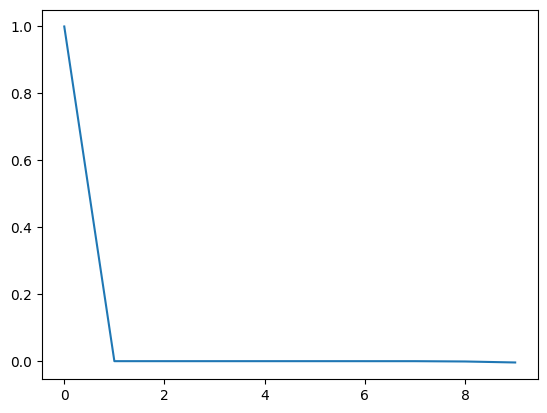

In [201]:
plt.plot(evals)

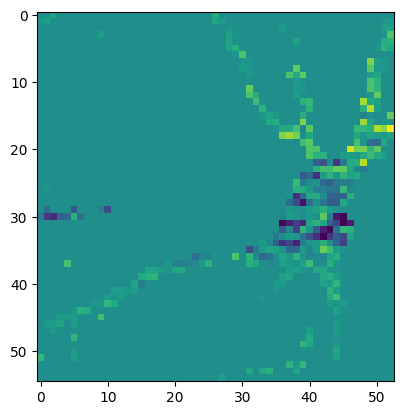

In [202]:
plt.imshow(recover(evecs[:, 0], A.shape, A_ixs), cmap="viridis")